Dataset Shape: (96360, 14)
transport_mode
Bus               1568694
Metro             4301048
Suburban Train    4094341
Name: passenger_count, dtype: int64


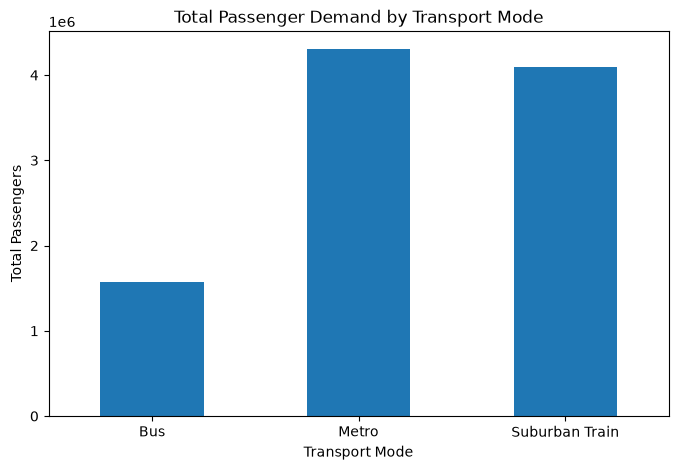

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv(
    "../dataset/processed/smarttransit_cleaned_2025.csv"
)

df["datetime"] = pd.to_datetime(df["datetime"])
df["date"] = pd.to_datetime(df["date"])

print("Dataset Shape:", df.shape)

mode_demand = df.groupby("transport_mode")["passenger_count"].sum()

print(mode_demand)

mode_demand.plot(kind="bar", figsize=(8, 5))

plt.title("Total Passenger Demand by Transport Mode")
plt.xlabel("Transport Mode")
plt.ylabel("Total Passengers")
plt.xticks(rotation=0)
plt.show()

hour
0       38054
1       23815
2       17077
3       17115
4       33221
5       95564
6      321831
7      589055
8      778446
9      665443
10     485161
11     423578
12     454582
13     435369
14     403291
15     457418
16     586144
17     828000
18    1010910
19     929499
20     687044
21     379455
22     209271
23      94740
Name: passenger_count, dtype: int64


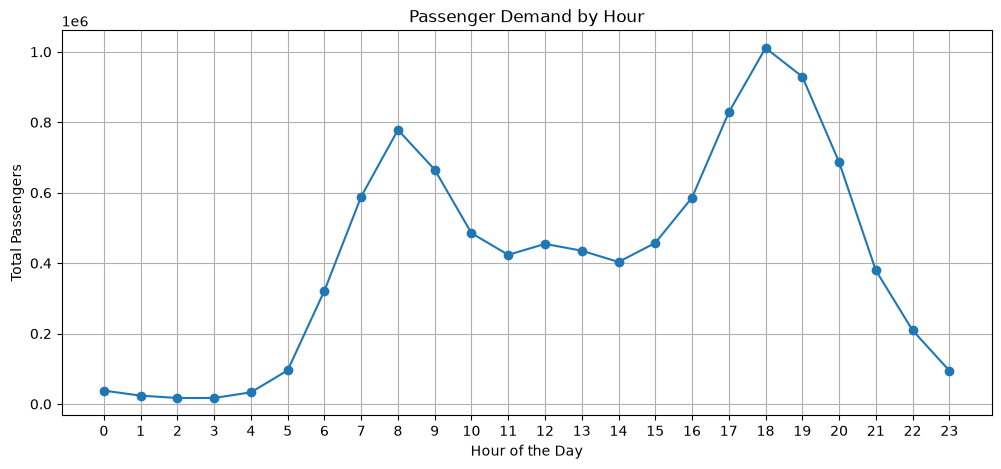

In [2]:
hourly_demand = df.groupby("hour")["passenger_count"].sum()

print(hourly_demand)

plt.figure(figsize=(12, 5))

hourly_demand.plot(kind="line", marker="o")

plt.title("Passenger Demand by Hour")
plt.xlabel("Hour of the Day")
plt.ylabel("Total Passengers")
plt.xticks(range(24))
plt.grid()
plt.show()

transport_mode  entity_name     
Suburban Train  Howrah              1433735
                Sealdah             1329953
Metro           Esplanade           1227344
                Sealdah Metro       1091536
                Dum Dum             1022026
                Park Street          960142
Suburban Train  Dum Dum Junction     785548
Bus             S-5                  614923
Suburban Train  Ballygunge           545105
Bus             AC-1                 510915
                AC-37B               442856
Name: passenger_count, dtype: int64


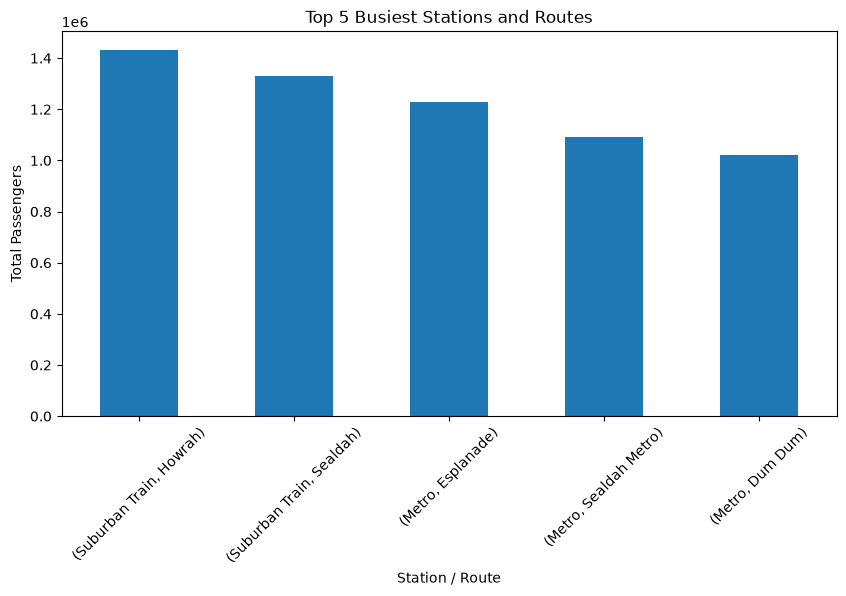

Weekday    111.260391
Weekend     83.690159
Name: passenger_count, dtype: float64


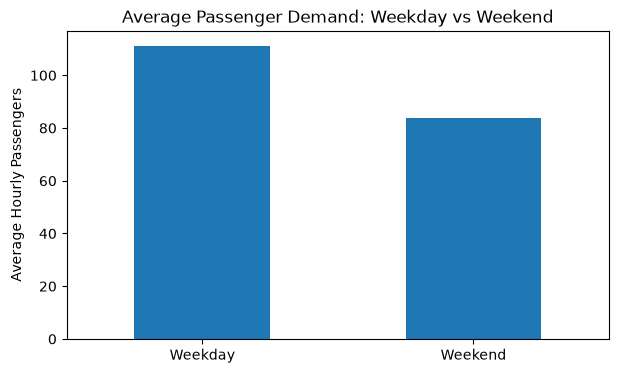

In [3]:
entity_demand = (
    df.groupby(["transport_mode", "entity_name"])["passenger_count"]
    .sum()
    .sort_values(ascending=False)
)

print(entity_demand)

top_entities = entity_demand.head(5)

top_entities.plot(kind="bar", figsize=(10, 5))

plt.title("Top 5 Busiest Stations and Routes")
plt.xlabel("Station / Route")
plt.ylabel("Total Passengers")
plt.xticks(rotation=45)
plt.show()

day_demand = df.groupby("is_weekend")["passenger_count"].mean()

day_demand.index = ["Weekday", "Weekend"]

print(day_demand)

day_demand.plot(kind="bar", figsize=(7, 4))

plt.title("Average Passenger Demand: Weekday vs Weekend")
plt.ylabel("Average Hourly Passengers")
plt.xticks(rotation=0)
plt.show()

## Initial EDA Findings

1. Howrah has the highest simulated passenger demand.
2. Sealdah suburban railway station also shows high demand.
3. The highest hourly passenger demand occurs at 6 PM.
4. Morning peak demand occurs around 8 AM.
5. Passenger demand is lowest during the early morning hours.
6. The dataset shows two major simulated rush-hour periods.